# The continuous-variable SWAP test

The SWAP test estimates the overlap $|\langle\psi|\phi\rangle|^2$ of two states. On a photonic processor it needs only
a 50:50 beamsplitter and photon counting ([arXiv:2202.09923](https://arxiv.org/abs/2202.09923)).

In [1]:
import warnings
warnings.filterwarnings("ignore", message=".*pkg_resources.*")           # emitted when strawberryfields is imported
warnings.filterwarnings("ignore", message=".*disconnected components.*")  # sf: programs on unentangled modes

import matplotlib.pyplot as plt
import numpy as np
import strawberryfields as sf
import torch
from strawberryfields import ops

from cv_relational_learning import fock
from cv_relational_learning.sf_simulation import estimate_swap_from_counts, run_swap_test, swap_test_shot

np.random.seed(0)  # strawberryfields samples photon counts with numpy's global RNG
COLORS = {"sf": "#2a78d6", "analytic": "#eb6834", "fock": "#1baf7a"}

## 1. SWAP gives the overlap

On a product state, $\langle\psi|\langle\phi|\,\mathrm{SWAP}\,|\psi\rangle|\phi\rangle = |\langle\psi|\phi\rangle|^2$.
Check with coherent states, where $|\langle\alpha|\beta\rangle|^2 = e^{-|\alpha-\beta|^2}$:

In [2]:
d = 15  # Fock cutoff used throughout this notebook
SWAP = fock.swap_operator(d)

def swap_expectation(psi, phi):
    # exact <SWAP> on the product state |psi>|phi> (flat kets of length d)
    return fock.expectation(torch.kron(psi, phi), SWAP).real.item()

for alpha, beta in [(0.5, 0.5), (0.5, -0.3 + 0.4j), (1.0, 0.0)]:
    psi = torch.tensor(fock.coherent_state(alpha, d))
    phi = torch.tensor(fock.coherent_state(beta, d))
    print(f"alpha = {alpha}, beta = {beta}:  <SWAP> = {swap_expectation(psi, phi):.6f}   "
          f"exp(-|alpha - beta|^2) = {np.exp(-abs(alpha - beta) ** 2):.6f}")

alpha = 0.5, beta = 0.5:  <SWAP> = 1.000000   exp(-|alpha - beta|^2) = 1.000000
alpha = 0.5, beta = (-0.3+0.4j):  <SWAP> = 0.449329   exp(-|alpha - beta|^2) = 0.449329
alpha = 1.0, beta = 0.0:  <SWAP> = 0.367879   exp(-|alpha - beta|^2) = 0.367879


## 2. Two squeezed vacua

For $S(r)|0\rangle$ and $S(-r)|0\rangle$ the overlap is $1/\cosh 2r$, with kets from `fock.squeezing` or from
strawberryfields:

In [3]:
def squeezed_vacuum(r, phi, d, d_big=40):
    # S|0> from fock.squeezing, built at a larger cutoff and truncated to d levels
    ket = fock.squeezing(torch.tensor(r, dtype=torch.float64), d_big, phi)[:d, 0]
    return ket / torch.linalg.norm(ket)

def sf_squeezed_vacuum(r, phi, d):
    # S|0> prepared with strawberryfields' Sgate (truncated ket)
    eng = sf.Engine("fock", backend_options={"cutoff_dim": d})
    prog = sf.Program(1)
    with prog.context as q:
        ops.Sgate(r, phi) | q[0]
    return torch.tensor(eng.run(prog).state.ket())

def squeezed_overlap(r1, phi1, r2, phi2):
    # analytic |<0|S(z1)^dag S(z2)|0>|^2
    return 1 / abs(np.cosh(r1) * np.cosh(r2) - np.exp(1j * (phi2 - phi1)) * np.sinh(r1) * np.sinh(r2))

print(f"{'(r1, phi1, r2, phi2)':>22}  {'analytic':>9}  {'fock kets':>9}  {'sf kets':>9}")
for r1, phi1, r2, phi2 in [(0.5, 0, -0.5, 0), (0.3, 0.2, 0.7, 1.4), (0.6, 0.0, 0.6, 2.0)]:
    with_fock = swap_expectation(squeezed_vacuum(r1, phi1, d), squeezed_vacuum(r2, phi2, d))
    with_sf = swap_expectation(sf_squeezed_vacuum(r1, phi1, d), sf_squeezed_vacuum(r2, phi2, d))
    print(f"{str((r1, phi1, r2, phi2)):>22}  {squeezed_overlap(r1, phi1, r2, phi2):9.6f}  {with_fock:9.6f}  {with_sf:9.6f}")

  (r1, phi1, r2, phi2)   analytic  fock kets    sf kets


     (0.5, 0, -0.5, 0)   0.648054   0.648054   0.648053


  (0.3, 0.2, 0.7, 1.4)   0.801862   0.801924   0.801863
  (0.6, 0.0, 0.6, 2.0)   0.618590   0.618614   0.618600


## 3. Measuring SWAP with a beamsplitter

After a 50:50 beamsplitter $B$, SWAP is the photon-number parity of one output mode,
$\mathrm{SWAP} = B^\dagger\,\big((-1)^{\hat n}\otimes 1\big)\,B$, so each shot records $(-1)^{n_0}$:

In [4]:
d_small = 8
B = fock.beamsplitter(d_small, np.pi / 4, 0)
parity_0 = torch.kron(fock.parity(d_small), fock.identity(d_small))
n_total = torch.arange(d_small)[:, None] + torch.arange(d_small)[None, :]
inside = (n_total < d_small).reshape(-1)

deviation = (B.conj().T @ parity_0 @ B - fock.swap_operator(d_small))[inside][:, inside]
print("max |B^dag (P x 1) B - SWAP| on n0 + n1 < d:", f"{deviation.abs().max().item():.1e}")

max |B^dag (P x 1) B - SWAP| on n0 + n1 < d: 7.8e-15


Simulated shots for the squeezed pair (`sf_simulation.swap_test_shot`):

In [5]:
r = 0.8
psi, phi = squeezed_vacuum(r, 0, d), squeezed_vacuum(-r, 0, d)
state = torch.kron(psi, phi).numpy().reshape(d, d)  # sf takes two-mode kets as (d, d) arrays

eng = sf.Engine("fock", backend_options={"cutoff_dim": d})
counts = np.array([swap_test_shot(state, eng) for _ in range(4000)])

print("first shots (n0, n1):", counts[:8].tolist())
print("shots with n0 != n1:", np.sum(counts[:, 0] != counts[:, 1]), "of", len(counts))
estimate = estimate_swap_from_counts(counts, d)
print(f"SWAP-test estimate: {estimate:.4f} +- {np.sqrt((1 - estimate**2) / len(counts)):.4f}   "
      f"exact (fock): {swap_expectation(psi, phi):.4f}   1/cosh(2r): {1 / np.cosh(2 * r):.4f}")

first shots (n0, n1): [[0, 0], [1, 1], [0, 0], [0, 0], [4, 4], [1, 1], [1, 1], [0, 0]]
shots with n0 != n1: 1 of 4000
SWAP-test estimate: 0.3725 +- 0.0147   exact (fock): 0.3881   1/cosh(2r): 0.3880


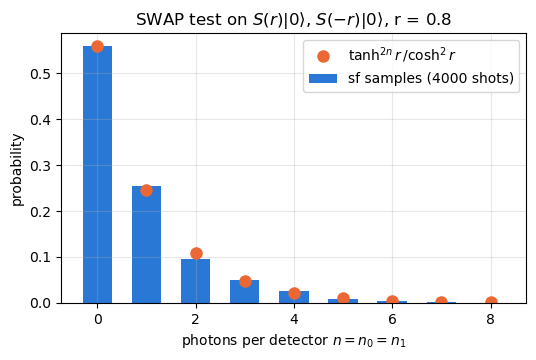

In [6]:
n = np.arange(9)
frequency = np.bincount(counts[:, 0], minlength=len(n))[: len(n)] / len(counts)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(n, frequency, width=0.6, color=COLORS["sf"], label=f"sf samples ({len(counts)} shots)")
ax.plot(n, np.tanh(r) ** (2 * n) / np.cosh(r) ** 2, "o", ms=8, color=COLORS["analytic"],
        label=r"$\tanh^{2n} r\, /\cosh^2 r$")
ax.set_xlabel(r"photons per detector $n = n_0 = n_1$")
ax.set_ylabel("probability")
ax.set_title(f"SWAP test on $S(r)|0\\rangle$, $S(-r)|0\\rangle$, r = {r}")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 4. Shot-based estimates

`run_swap_test` against the exact overlap:

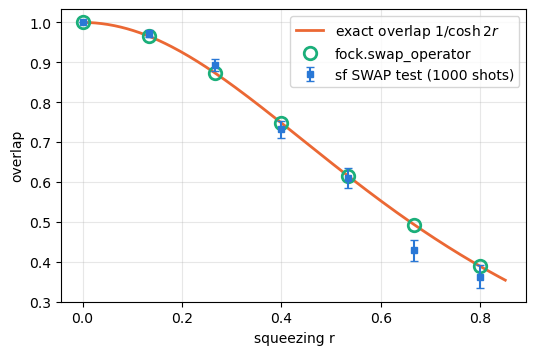

In [7]:
shots = 1000
rs = np.linspace(0, 0.8, 7)
exact, estimated = [], []
for r_ in rs:
    psi, phi = squeezed_vacuum(r_, 0, d), squeezed_vacuum(-r_, 0, d)
    exact.append(swap_expectation(psi, phi))
    estimated.append(run_swap_test(torch.kron(psi, phi).numpy().reshape(d, d), d, shots))
exact, estimated = np.array(exact), np.array(estimated)

r_fine = np.linspace(0, 0.85, 200)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(r_fine, 1 / np.cosh(2 * r_fine), color=COLORS["analytic"], lw=2, label=r"exact overlap $1/\cosh 2r$")
ax.plot(rs, exact, "o", ms=9, mfc="none", mew=2, color=COLORS["fock"], label="fock.swap_operator")
ax.errorbar(rs, estimated, yerr=np.sqrt((1 - exact**2) / shots), fmt="s", ms=5, capsize=3,
            color=COLORS["sf"], label=f"sf SWAP test ({shots} shots)")
ax.set_xlabel("squeezing r")
ax.set_ylabel("overlap")
ax.grid(alpha=0.3)
ax.legend()
plt.show()